# Data Inventory & EDA — Adaptive Retrieval Routing Thesis

**Mục đích:** rà soát TOÀN BỘ nguồn dữ liệu đã thu thập trong project (structured MySQL,
RAG corpus trong pgvector, market snapshot, causal panel, evaluation benchmark) *trước khi*
quyết định kiến trúc cho các thành phần ML sắp xây (learned router / market-regime
classifier / ABSA) — xem `docs/PROGRESS.md` và cuộc thảo luận gần nhất trong phiên làm việc
với Claude để biết bối cảnh đầy đủ.

Notebook này **chỉ đọc dữ liệu** (không ghi/sửa gì). Chạy trực tiếp trên máy đã có:
- Docker MySQL + pgvector đang chạy (`docker compose up -d`)
- `.venv` của project đã cài đủ dependency (không cần Ollama — notebook này không dùng LLM)
- Kernel Jupyter trỏ vào `.venv/bin/python` của chính project

Mỗi phần dưới đây được bọc trong `try/except` — nếu một bảng/file nào đó rỗng hoặc chưa
tồn tại, cell sẽ in cảnh báo rõ ràng thay vì làm vỡ toàn bộ notebook. **Bản thân những cảnh
báo đó cũng là một phát hiện quan trọng** (nguồn dữ liệu nào còn thiếu/rỗng), không phải lỗi
cần bỏ qua.


In [1]:
import sys, re, warnings
import traceback
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").exists(), "Chay notebook nay tu thu muc goc project (co folder src/)"
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 4)
warnings.filterwarnings("ignore")

from src.core.db import engine, check_connection
from src.core import config as cfg

print("MySQL connection: ", end="")
mysql_ok = check_connection()

from sqlalchemy import create_engine as _create_engine
pg_engine = _create_engine(
    f"postgresql+psycopg2://{cfg.PGVECTOR_USER}:{cfg.PGVECTOR_PASSWORD}"
    f"@{cfg.PGVECTOR_HOST}:{cfg.PGVECTOR_PORT}/{cfg.PGVECTOR_DB}"
)
try:
    with pg_engine.connect() as conn:
        pass
    print("pgvector (Postgres) connection: OK")
    pg_ok = True
except Exception as e:
    print(f"pgvector (Postgres) connection: FAILED - {type(e).__name__}: {e}")
    traceback.print_exc()
    pg_ok = False


MySQL connection: OK - connected to localhost:3307/financial_db
pgvector (Postgres) connection: OK


## 1. Companies & reference universe

Ba nguồn: bảng `companies` (MySQL, universe đang track thật), file
`data/reference/top200_candidate_companies.csv` (độ đầy đủ dữ liệu theo công ty), file
`data/reference/ticker_sector_map.csv` (map ticker -> ngành Vietstock, toàn bộ ~4005 mã).


In [2]:
try:
    companies = pd.read_sql("SELECT * FROM companies", engine)
    print(f"companies: {len(companies)} rows")
    display(companies.groupby("exchange").size().sort_values(ascending=False).rename("count"))
    display(companies.groupby("sector").size().sort_values(ascending=False).rename("count"))
except Exception as e:
    print(f"[canh bao] khong doc duoc bang companies: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    companies = pd.DataFrame()


companies: 216 rows


exchange
HOSE     87
UPCOM    72
HNX      50
OTC       6
KHÁC      1
Name: count, dtype: int64

sector
Nguyên vật liệu                                      35
Thực phẩm, đồ uống và thuốc lá                       32
Hàng hóa công nghiệp                                 22
Bất động sản                                         21
Dịch vụ tài chính                                    19
Tiện ích                                             16
Vận tải                                              15
Năng lượng                                            8
Bảo hiểm                                              7
Thương mại hàng không thiết yếu                       6
Thời trang và hàng lâu bền                            5
Tiêu dùng không thiết yếu (Bán lẻ)                    4
Công nghiệp chế biến                                  4
Truyền thông và giải trí                              4
Dịch vụ viễn thông                                    4
Tiêu dùng thiết yếu                                   4
Thiết bị và dịch vụ chăm sóc sức khỏe                 2
Thương mại hàng thiết yếu                

top200_candidate_companies.csv: 200 rows


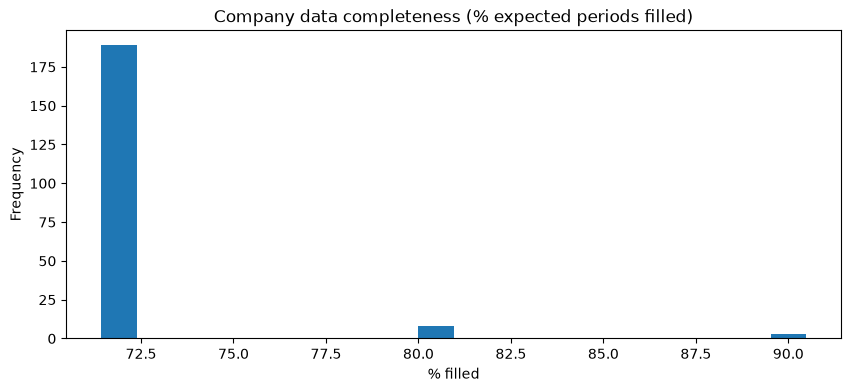

10 cong ty co do phu du lieu THAP nhat (uu tien kiem tra truoc khi dung lam benchmark/panel):


,ticker,company_name,filled,total_real_periods,completeness_pct
99,BRC,CTCP Cao su Bến Thành,15,21,71.428571
127,CAG,CTCP Cảng An Giang,15,21,71.428571
128,CAN,CTCP Đồ hộp Hạ Long,15,21,71.428571
129,CBI,CTCP Gang thép Cao Bằng,15,21,71.428571
130,CC1,Tổng Công ty Xây dựng Số 1 - CTCP,15,21,71.428571
131,CCA,CTCP Xuất nhập khẩu Thuỷ sản Cần Thơ,15,21,71.428571
132,CCI,CTCP Đầu tư Phát triển Công nghiệp Thương mại ...,15,21,71.428571
133,CCL,CTCP Đầu tư và Phát triển Đô thị Dầu khí Cửu Long,15,21,71.428571
134,CCR,CTCP Cảng Cam Ranh,15,21,71.428571
135,CCT,CTCP Cảng Cần Thơ,15,21,71.428571


In [3]:
try:
    top200 = pd.read_csv(PROJECT_ROOT / "data/reference/top200_candidate_companies.csv")
    print(f"top200_candidate_companies.csv: {len(top200)} rows")
    top200["completeness_pct"] = top200["filled"] / top200["total_real_periods"] * 100
    top200["completeness_pct"].plot(kind="hist", bins=20, title="Company data completeness (% expected periods filled)")
    plt.xlabel("% filled"); plt.show()
    print("10 cong ty co do phu du lieu THAP nhat (uu tien kiem tra truoc khi dung lam benchmark/panel):")
    display(top200.sort_values("completeness_pct")[["ticker", "company_name", "filled", "total_real_periods", "completeness_pct"]].head(10))
except Exception as e:
    print(f"[canh bao] khong doc duoc top200_candidate_companies.csv: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    top200 = pd.DataFrame()


ticker_sector_map.csv: 200 rows (toan bo universe Vietstock)


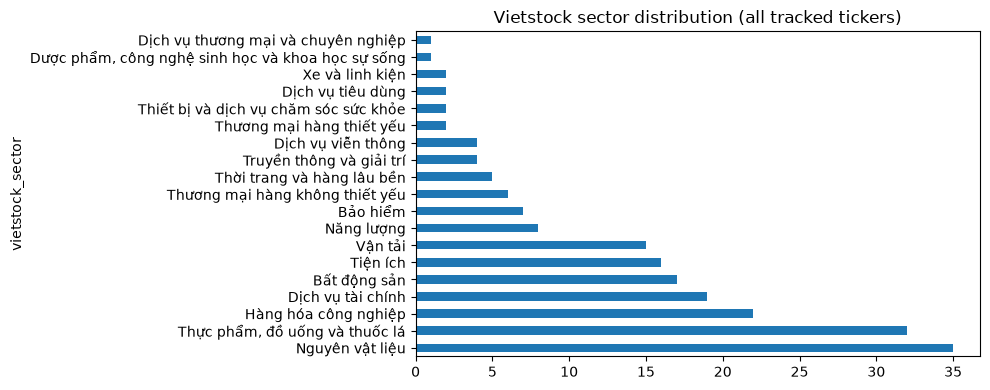

200/216 cong ty trong `companies` co sector map thanh cong


In [4]:
try:
    sector_map = pd.read_csv(PROJECT_ROOT / "data/reference/ticker_sector_map.csv")
    print(f"ticker_sector_map.csv: {len(sector_map)} rows (toan bo universe Vietstock)")
    sector_map["vietstock_sector"].value_counts().plot(kind="barh", title="Vietstock sector distribution (all tracked tickers)")
    plt.tight_layout(); plt.show()
    if not companies.empty:
        coverage = companies.merge(sector_map, on="ticker", how="left")
        n_matched = coverage["vietstock_sector"].notna().sum()
        print(f"{n_matched}/{len(coverage)} cong ty trong `companies` co sector map thanh cong")
except Exception as e:
    print(f"[canh bao] khong doc duoc ticker_sector_map.csv: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    sector_map = pd.DataFrame()


## 2. Structured financial data (DAG path) — `financial_line_items` / `financial_ratios` / `disclosures`

Đây là dữ liệu nền cho nhánh DAG, What-if calculator, và panel dataset của causal ML.
Quan trọng nhất ở đây: **coverage matrix ticker × năm** — cho biết công ty nào/năm nào thực
sự có đủ số liệu để dùng làm câu hỏi benchmark hoặc quan sát trong panel, tránh chọn phải
ticker/năm rỗng dữ liệu.


In [5]:
try:
    fli = pd.read_sql(
        "SELECT ticker, fiscal_year, period, statement_type, ms_code, consolidation, value "
        "FROM financial_line_items", engine)
    print(f"financial_line_items: {len(fli):,} rows, {fli['ticker'].nunique()} distinct tickers, "
          f"nam {fli['fiscal_year'].min()}-{fli['fiscal_year'].max()}")
    display(fli["period"].value_counts().rename("count"))
    display(fli["statement_type"].value_counts().rename("count"))
    display(fli["consolidation"].value_counts().rename("count"))
except Exception as e:
    print(f"[canh bao] khong doc duoc financial_line_items: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    fli = pd.DataFrame()


financial_line_items: 21,982 rows, 14 distinct tickers, nam 2024-2026


period
Q1      4259
H1      3894
9M      3177
YEAR    3025
Q2      2966
Q3      2442
Q4      2219
Name: count, dtype: int64

statement_type
balance_sheet         13774
income_statement       4707
cash_flow_indirect     3056
cash_flow_direct        445
Name: count, dtype: int64

consolidation
standalone      11171
consolidated    10811
Name: count, dtype: int64

Coverage matrix (YEAR period): 14 tickers x 2 years


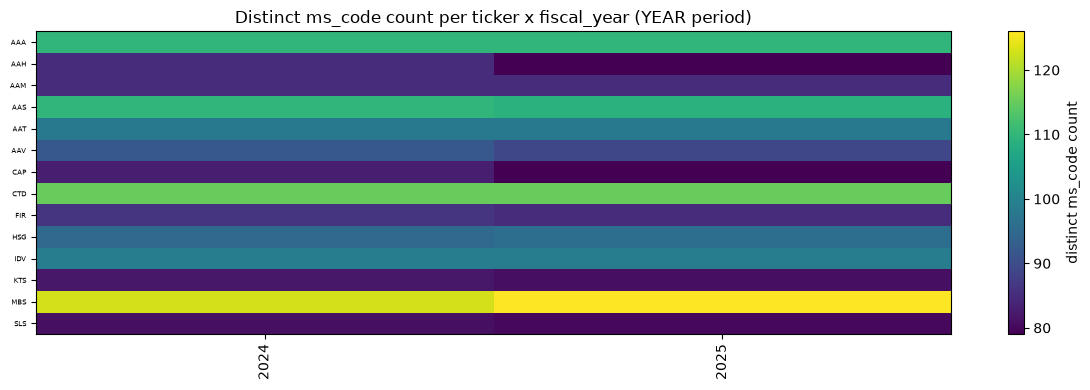

In [6]:
try:
    year_rows = fli[fli["period"] == "YEAR"]
    coverage_matrix = year_rows.pivot_table(
        index="ticker", columns="fiscal_year", values="ms_code", aggfunc="nunique", fill_value=0
    )
    print(f"Coverage matrix (YEAR period): {coverage_matrix.shape[0]} tickers x {coverage_matrix.shape[1]} years")
    fig, ax = plt.subplots(figsize=(12, max(4, coverage_matrix.shape[0] * 0.12)))
    im = ax.imshow(coverage_matrix.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(coverage_matrix.columns))); ax.set_xticklabels(coverage_matrix.columns, rotation=90)
    ax.set_yticks(range(len(coverage_matrix.index))); ax.set_yticklabels(coverage_matrix.index, fontsize=5)
    ax.set_title("Distinct ms_code count per ticker x fiscal_year (YEAR period)")
    fig.colorbar(im, label="distinct ms_code count")
    plt.tight_layout(); plt.show()

    zero_cols = coverage_matrix.columns[(coverage_matrix == 0).all(axis=0)]
    if len(zero_cols):
        print(f"[luu y] cac nam KHONG co du lieu o bat ky ticker nao: {list(zero_cols)}")
except Exception as e:
    print(f"[canh bao] khong ve duoc coverage matrix: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()


In [7]:
try:
    fratios = pd.read_sql(
        "SELECT ticker, fiscal_year, period, ratio_group, ratio_name, value FROM financial_ratios", engine)
    print(f"financial_ratios: {len(fratios):,} rows, {fratios['ticker'].nunique()} distinct tickers")
    display(fratios["ratio_group"].value_counts().rename("count"))
    display(fratios["ratio_name"].value_counts().head(15).rename("count"))
except Exception as e:
    print(f"[canh bao] khong doc duoc financial_ratios (co the con rong - PROGRESS.md ghi 'co du lieu nhung chua co DAG lookup'): {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    fratios = pd.DataFrame()


financial_ratios: 9,936 rows, 14 distinct tickers


ratio_group
NHÓM CHỈ SỐ DÒNG TIỀN             2830
NHÓM CHỈ SỐ ĐỊNH GIÁ              1467
NHÓM CHỈ SỐ HIỆU QUẢ HOẠT ĐỘNG    1329
NHÓM CHỈ SỐ TĂNG TRƯỞNG           1249
NHÓM CHỈ SỐ SINH LỢI              1139
NHÓM CHỈ SỐ ĐÒN BẨY TÀI CHÍNH     1098
NHÓM CHỈ SỐ THANH KHOẢN            824
Name: count, dtype: int64

ratio_name
Tỷ suất cổ tức                                                         230
Giá trị sổ sách của cổ phiếu (BVPS)                                    221
Khả năng thanh toán lãi vay                                            198
Giá trị doanh nghiệp trên lợi nhuận trước thuế và lãi vay (EV/EBIT)    198
Tỷ suất lợi nhuận trên vốn chủ sở hữu bình quân (ROEA)                 195
Tỷ suất sinh lợi trên tổng tài sản bình quân (ROAA)                    195
Tài sản ngắn hạn/Tổng tài sản                                          164
Tiền/Tài sản ngắn hạn                                                  164
Tỷ số thanh toán hiện hành (ngắn hạn)                                  164
Chỉ số giá thị trường trên thu nhập (P/E)                              164
Tỷ số Nợ ngắn hạn trên Tổng nợ phải trả                                164
Tỷ số Nợ trên Tổng tài sản                                             164
Tỷ số Vốn chủ sở hữu trên Tổng tài sản                                 164
Tỷ số Nợ ngắn 

In [8]:
try:
    disclosures = pd.read_sql(
        "SELECT ticker, fiscal_year, period, report_type, audit_status, auditor, structure_valid FROM disclosures", engine)
    print(f"disclosures: {len(disclosures):,} rows")
    display(disclosures["report_type"].value_counts().rename("count"))
    display(disclosures["audit_status"].value_counts(dropna=False).rename("count"))
    display(disclosures["structure_valid"].value_counts(dropna=False).rename("count"))
except Exception as e:
    print(f"[canh bao] khong doc duoc disclosures: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    disclosures = pd.DataFrame()


disclosures: 234 rows


report_type
quy         138
ban_nien     68
nam          28
Name: count, dtype: int64

audit_status
Chưa kiểm toán    169
Soát xét           37
Kiểm toán          28
Name: count, dtype: int64

structure_valid
None    234
Name: count, dtype: int64

## 3. Macro & market-factor indicators (`macro_indicators`)

Bao gồm cả macro vĩ mô (CPI, GDP, PMI, ...) lẫn 4 chuỗi thị trường hàng ngày dùng cho
market-regime classifier (RQ3): `MKT_VNINDEX`, `MKT_GOLD_SJC`, `MKT_FOREX_VCB`, `MKT_OIL_WTI`.
Phần cuối cell này trực tiếp trả lời: **có đủ độ dài chuỗi thời gian để train một regime
classifier có ý nghĩa hay chưa?**


In [9]:
try:
    macro = pd.read_sql(
        "SELECT category, indicator_name, unit, period_type, fiscal_year, period, value FROM macro_indicators", engine)
    print(f"macro_indicators: {len(macro):,} rows")
    display(macro["category"].value_counts().rename("count"))
    display(macro["period_type"].value_counts().rename("count"))
except Exception as e:
    print(f"[canh bao] khong doc duoc macro_indicators: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    macro = pd.DataFrame()


macro_indicators: 33,209 rows


category
EXPORTS_BY_COUNTRY                      4118
IMPORTS_BY_COUNTRY                      4072
DEPOSIT_RATES                           3450
IMPORTS_BY_COMMODITY                    2626
EXPORTS_BY_COMMODITY                    2416
IIP                                     2220
INDUSTRIAL_VOLUME                       1980
STATE_BUDGET_INVESTMENT                 1639
CPI                                     1080
BALANCE_OF_PAYMENTS                      867
FDI_BY_INDUSTRY                          855
XPI                                      620
MPI                                      600
GDP_NOMINAL                              560
GDP_REAL                                 560
GDP_REAL_GROWTH                          560
GDP_NOMINAL_STRUCTURE                    540
VNIBOR                                   427
STATE_BUDGET_REVENUE                     390
BUSINESS_REGISTRATION                    360
PPI                                      320
KEY_INDUSTRIAL_PRODUCTS                  312
R

period_type
MONTH      22242
QUARTER     5244
DAILY       4259
YEAR         944
YTD          520
Name: count, dtype: int64

In [10]:
MKT_CATEGORIES = {
    "MKT_VNINDEX": "VN-Index (close)",
    "MKT_GOLD_SJC": None,      # nhieu indicator_name khac nhau (SJC mua/ban theo chi nhanh)
    "MKT_FOREX_VCB": None,     # nhieu currency
    "MKT_OIL_WTI": "WTI crude (Cushing, OK)",
}

if not macro.empty:
    mkt = macro[macro["category"].isin(MKT_CATEGORIES)].copy()
    print(f"Market-factor rows (regime-classifier candidates): {len(mkt):,}")
    if mkt.empty:
        print("[QUAN TRONG] Khong co du lieu MKT_* nao trong macro_indicators - "
              "thesis_market_snapshot Airflow DAG co the chua chay du lau, hoac chua chay lan nao. "
              "Day la dieu kien tien quyet truoc khi xay market-regime classifier (RQ3).")
    else:
        for cat in MKT_CATEGORIES:
            sub = mkt[mkt["category"] == cat]
            if sub.empty:
                print(f"  {cat}: KHONG CO DU LIEU")
                continue
            n_days = sub["period"].nunique()
            print(f"  {cat}: {len(sub)} rows, {n_days} distinct period-points, "
                  f"nam {sub['fiscal_year'].min()}-{sub['fiscal_year'].max()}, "
                  f"{sub['indicator_name'].nunique()} indicator_name khac nhau")
else:
    mkt = pd.DataFrame()


Market-factor rows (regime-classifier candidates): 292
  MKT_VNINDEX: 262 rows, 251 distinct period-points, nam 2025-2026, 1 indicator_name khac nhau
  MKT_GOLD_SJC: 4 rows, 2 distinct period-points, nam 2026-2026, 2 indicator_name khac nhau
  MKT_FOREX_VCB: 26 rows, 2 distinct period-points, nam 2026-2026, 13 indicator_name khac nhau
  MKT_OIL_WTI: KHONG CO DU LIEU


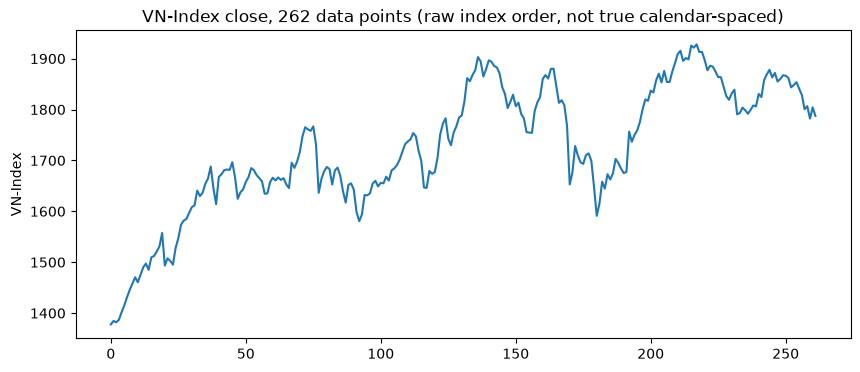

[luu y] truc x o day la THU TU ban ghi, khong phai khoang cach thoi gian that - neu chuoi co ngay nghi/le bi thieu, do thi nay se khong the hien duoc gap do. Can kiem tra rieng do lien tuc cua period truoc khi dung cho regime classifier.


In [11]:
# Ve chuoi thoi gian VN-Index rieng (chuoi quan trong nhat cho regime classifier)
if not mkt.empty:
    vnindex = mkt[(mkt["category"] == "MKT_VNINDEX")].copy()
    if not vnindex.empty:
        vnindex["date_sort_key"] = vnindex["fiscal_year"].astype(str) + "-" + vnindex["period"].astype(str)
        vnindex = vnindex.sort_values("date_sort_key")
        vnindex["value"].astype(float).reset_index(drop=True).plot(title=f"VN-Index close, {len(vnindex)} data points (raw index order, not true calendar-spaced)")
        plt.ylabel("VN-Index"); plt.show()
        print("[luu y] truc x o day la THU TU ban ghi, khong phai khoang cach thoi gian that - "
              "neu chuoi co ngay nghi/le bi thieu, do thi nay se khong the hien duoc gap do. "
              "Can kiem tra rieng do lien tuc cua period truoc khi dung cho regime classifier.")
    else:
        print("[canh bao] khong co du lieu MKT_VNINDEX de ve")


## 4. Company price snapshot (`company_price_snapshot`)

Giá đóng cửa/khối lượng hàng ngày theo từng ticker (từ `market_snapshot.py`) — dùng cho
COMPARE branch và tiềm năng làm feature cho regime/reranking.


In [12]:
try:
    prices = pd.read_sql(
        "SELECT ticker, trade_date, close_price, volume FROM company_price_snapshot", engine)
    print(f"company_price_snapshot: {len(prices):,} rows, {prices['ticker'].nunique()} tickers, "
          f"{prices['trade_date'].nunique()} distinct trade_date")
    if not prices.empty:
        print(f"date range: {prices['trade_date'].min()} -> {prices['trade_date'].max()}")
        display(prices.groupby("ticker").size().sort_values(ascending=False).rename("n_days").head(20))
except Exception as e:
    print(f"[canh bao] khong doc duoc company_price_snapshot (co the con rong neu Airflow DAG moi chay it lan): {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    prices = pd.DataFrame()


company_price_snapshot: 41,400 rows, 207 tickers, 669 distinct trade_date
date range: 2023-11-08 -> 2026-07-17


ticker
AAA    262
ALT    262
AGF    262
AGG    262
AGM    262
AGP    262
AGR    262
AIC    262
AIG    262
AME    262
ADS    262
AMP    262
AMS    262
AMV    262
ANT    262
ANV    262
APC    262
AAH    262
AFX    262
AMC    262
Name: n_days, dtype: int64

## 5. Causal panel dataset (input cho T-learner, `src/causal/treatment_effect.py`)

Đây là thành phần ML **thật** duy nhất đã có trong hệ thống hiện tại (RQ6). Kiểm tra kỹ ở
đây để biết: panel có đủ lớn không, mỗi cặp treatment→outcome (`_CAUSAL_CONCEPTS` trong
`src/router/rules.py`) có đủ phương sai/số quan sát không thiếu để ước lượng ATE có ý nghĩa.


In [13]:
try:
    from src.causal.panel_builder import build_panel
    panel = build_panel()
    print(f"Panel shape: {panel.shape[0]} ticker-period rows x {panel.shape[1]} columns")
    if not panel.empty:
        display(panel.groupby("sector").size().sort_values(ascending=False).rename("count"))
        display(panel.groupby("fiscal_year").size().rename("count"))
except Exception as e:
    print(f"[canh bao] build_panel() loi: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    panel = pd.DataFrame()


[panel_builder] excluded 288 finance-subsector line-item rows and 2/24 ticker-period rows with out-of-range ratios (likely schema mismatch, not real data).
Panel shape: 22 ticker-period rows x 29 columns


sector
Nguyên vật liệu                   6
Bất động sản                      5
Thực phẩm, đồ uống và thuốc lá    5
Hàng hóa công nghiệp              2
Năng lượng                        2
Thời trang và hàng lâu bền        2
Name: count, dtype: int64

fiscal_year
2024    11
2025    11
Name: count, dtype: int64

Missingness (%) cho tung cot dung trong causal panel:


gold_price_annual_avg    100.0
usdvnd_annual_avg        100.0
oil_price_annual_avg     100.0
ocf_to_revenue             9.1
leverage                   0.0
current_ratio              0.0
gross_margin               0.0
net_margin                 0.0
asset_turnover             0.0
cpi_annual_avg             0.0
gdp_growth_annual_avg      0.0
Name: % missing, dtype: float64

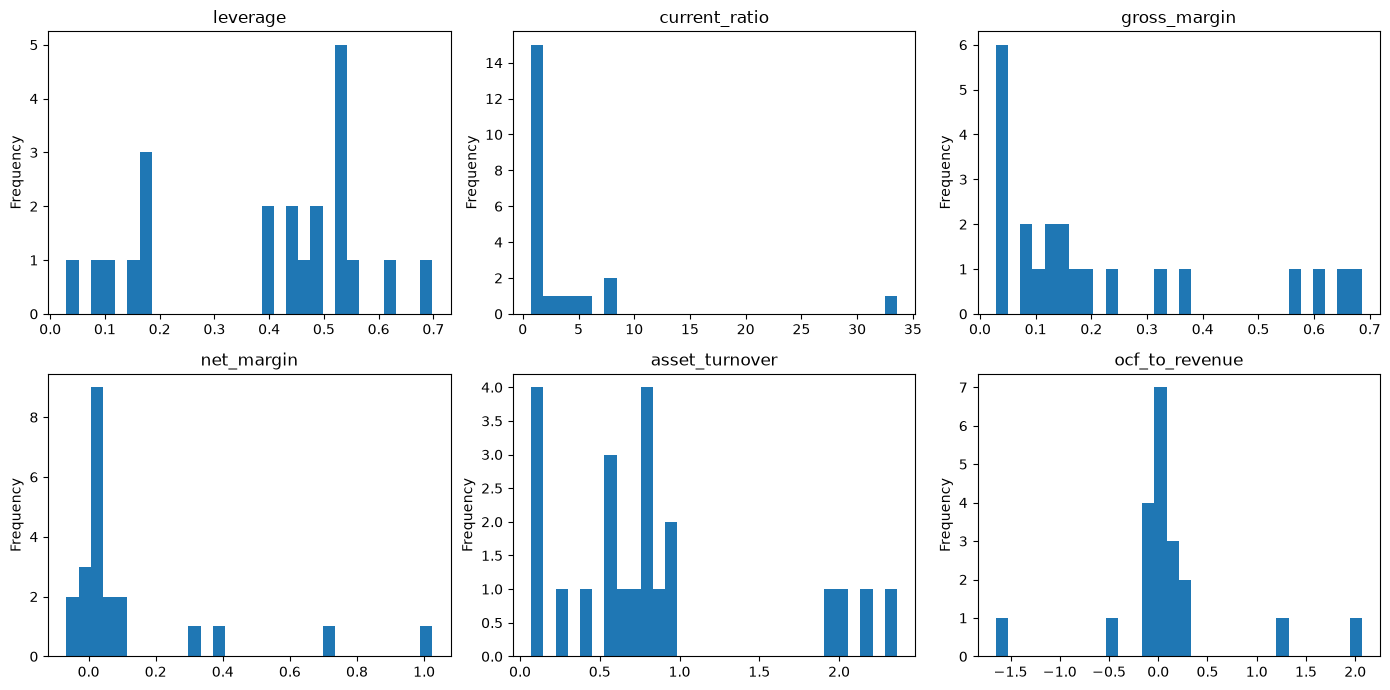


So quan sat non-null cho tung ratio (can du lon de T-learner fit rieng cho treated/control):


leverage          22
current_ratio     22
gross_margin      22
net_margin        22
asset_turnover    22
ocf_to_revenue    20
Name: n_non_null, dtype: int64

In [14]:
RATIO_COLS = ["leverage", "current_ratio", "gross_margin", "net_margin", "asset_turnover", "ocf_to_revenue"]
COVARIATE_COLS = ["cpi_annual_avg", "gdp_growth_annual_avg", "gold_price_annual_avg",
                   "usdvnd_annual_avg", "oil_price_annual_avg"]

if not panel.empty:
    print("Missingness (%) cho tung cot dung trong causal panel:")
    miss = panel[RATIO_COLS + COVARIATE_COLS].isna().mean().sort_values(ascending=False) * 100
    display(miss.round(1).rename("% missing"))

    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, col in zip(axes.flat, RATIO_COLS):
        panel[col].dropna().plot(kind="hist", bins=30, ax=ax, title=col)
    plt.tight_layout(); plt.show()

    print("\nSo quan sat non-null cho tung ratio (can du lon de T-learner fit rieng cho treated/control):")
    display(panel[RATIO_COLS].notna().sum().rename("n_non_null"))


In [15]:
# Cac cap treatment -> outcome ma router (rules.py) co the route sang nhanh causal.
# Kiem tra rieng tung cap: co bao nhieu hang co CA HAI cot khong null (dieu kien toi thieu de T-learner dung duoc).
CAUSAL_PAIRS = [
    ("leverage", "net_margin"),
    ("leverage", "gross_margin"),
    ("gross_margin", "net_margin"),
    ("asset_turnover", "net_margin"),
    ("current_ratio", "net_margin"),
    ("ocf_to_revenue", "net_margin"),
]

if not panel.empty:
    print("So quan sat kha dung cho tung cap (treatment, outcome) - dieu kien can de RQ6 T-learner co y nghia thong ke:")
    for t, o in CAUSAL_PAIRS:
        if t in panel.columns and o in panel.columns:
            n = panel[[t, o]].dropna().shape[0]
            flag = "" if n >= 30 else "  <-- CO THE QUA IT (kinh nghiem: can >=30 quan sat/nhom)"
            print(f"  {t:16s} -> {o:16s}: {n:4d} quan sat co du lieu{flag}")


So quan sat kha dung cho tung cap (treatment, outcome) - dieu kien can de RQ6 T-learner co y nghia thong ke:
  leverage         -> net_margin      :   22 quan sat co du lieu  <-- CO THE QUA IT (kinh nghiem: can >=30 quan sat/nhom)
  leverage         -> gross_margin    :   22 quan sat co du lieu  <-- CO THE QUA IT (kinh nghiem: can >=30 quan sat/nhom)
  gross_margin     -> net_margin      :   22 quan sat co du lieu  <-- CO THE QUA IT (kinh nghiem: can >=30 quan sat/nhom)
  asset_turnover   -> net_margin      :   22 quan sat co du lieu  <-- CO THE QUA IT (kinh nghiem: can >=30 quan sat/nhom)
  current_ratio    -> net_margin      :   22 quan sat co du lieu  <-- CO THE QUA IT (kinh nghiem: can >=30 quan sat/nhom)
  ocf_to_revenue   -> net_margin      :   20 quan sat co du lieu  <-- CO THE QUA IT (kinh nghiem: can >=30 quan sat/nhom)


## 6. RAG corpus (`disclosure_chunks` trong pgvector)

Toàn bộ corpus dùng cho nhánh RAG (TiniX OCR + PDF thật text-native). Phần PCA embedding ở
cuối chỉ mang tính khám phá cấu trúc không gian embedding (không phải phân tích thống kê
chính thức) — giúp trực quan hoá liệu các doctype có tách biệt rõ trong không gian embedding
hay không (liên quan gián tiếp tới việc BM25/hybrid retrieval có đáng làm không, đã bàn tới
trong phiên làm việc trước).


disclosure_chunks: 13,750 rows
has_embedding: 13,750/13,750


ticker
VNM    4991
PNJ    4976
CTD    3783
Name: count, dtype: int64

doctype
financial_statement    13504
other                    246
Name: count, dtype: int64

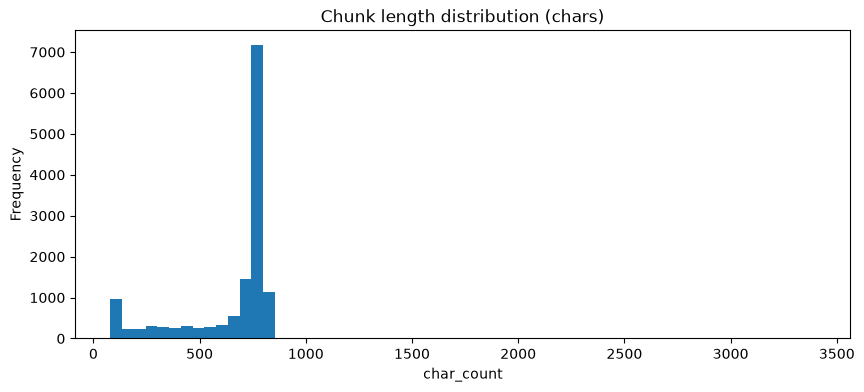

In [16]:
if pg_ok:
    try:
        chunks_meta = pd.read_sql("""
            SELECT ticker, doctype, source_file, page, chunk_index, char_count,
                   (embedding IS NOT NULL) AS has_embedding
            FROM disclosure_chunks
        """, pg_engine)
        print(f"disclosure_chunks: {len(chunks_meta):,} rows")
        print(f"has_embedding: {chunks_meta['has_embedding'].sum():,}/{len(chunks_meta):,}")
        display(chunks_meta["ticker"].value_counts().rename("count"))
        display(chunks_meta["doctype"].value_counts().rename("count"))
        chunks_meta["char_count"].plot(kind="hist", bins=60, title="Chunk length distribution (chars)")
        plt.xlabel("char_count"); plt.show()
    except Exception as e:
        print(f"[canh bao] khong doc duoc disclosure_chunks: {type(e).__name__}: {e}")
        import traceback; traceback.print_exc()
        chunks_meta = pd.DataFrame()
else:
    print("[bo qua] pgvector chua ket noi duoc - xem canh bao o cell setup phia tren")
    chunks_meta = pd.DataFrame()


In [17]:
_YEAR_RE = re.compile(r"(?<!\d)(20\d{2})(?!\d)")

if not chunks_meta.empty:
    chunks_meta["year"] = chunks_meta["source_file"].apply(
        lambda s: (lambda m: int(m.group(1)) if m else None)(_YEAR_RE.search(s))
    )
    display(chunks_meta["year"].value_counts(dropna=False).sort_index().rename("count"))
    n_no_year = chunks_meta["year"].isna().sum()
    print(f"{n_no_year:,}/{len(chunks_meta):,} chunk KHONG trich xuat duoc nam tu ten file "
          f"(anh huong truc tiep den RQ4 Temporal Anchor Filtering - nhung chunk nay khong the anchor theo nam)")

    ticker_doctype = pd.crosstab(chunks_meta["ticker"], chunks_meta["doctype"])
    print("\nTicker x doctype crosstab (top 15 ticker theo tong so chunk):")
    display(ticker_doctype.loc[ticker_doctype.sum(axis=1).sort_values(ascending=False).head(15).index])


year
2015    1228
2016    1132
2017    1120
2018    1178
2019    1144
2020    1356
2021    1235
2022    1352
2023     788
2024    1361
2025    1856
Name: count, dtype: int64

0/13,750 chunk KHONG trich xuat duoc nam tu ten file (anh huong truc tiep den RQ4 Temporal Anchor Filtering - nhung chunk nay khong the anchor theo nam)

Ticker x doctype crosstab (top 15 ticker theo tong so chunk):


doctype,financial_statement,other
ticker,,
VNM,4745,246
PNJ,4976,0
CTD,3783,0


Sampled embedding matrix: (3000, 1024)
explained variance ratio (2 components): [0.08  0.061] (thap la binh thuong - embedding 1024-dim khong ky vong nen duoc het vao 2D)


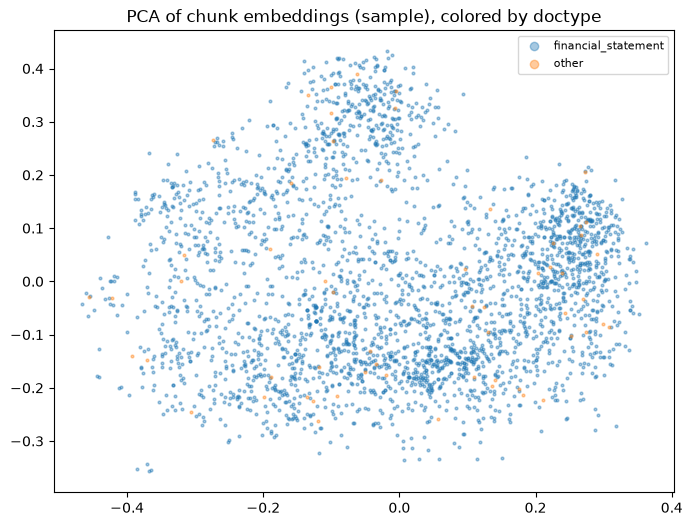

In [18]:
# PCA kham pha khong gian embedding (sample de nhanh) - CAN pg_ok va co chunks co embedding
if pg_ok and not chunks_meta.empty and chunks_meta["has_embedding"].sum() > 0:
    try:
        sample = pd.read_sql("""
            SELECT ticker, doctype, embedding::text AS embedding_text
            FROM disclosure_chunks
            WHERE embedding IS NOT NULL
            ORDER BY random()
            LIMIT 3000
        """, pg_engine)

        def _parse_vec(s):
            return np.fromstring(s.strip("[]"), sep=",")

        X = np.vstack(sample["embedding_text"].apply(_parse_vec).values)
        print(f"Sampled embedding matrix: {X.shape}")

        from sklearn.decomposition import PCA
        pca = PCA(n_components=2, random_state=0)
        X2 = pca.fit_transform(X)
        print(f"explained variance ratio (2 components): {pca.explained_variance_ratio_.round(3)} "
              f"(thap la binh thuong - embedding 1024-dim khong ky vong nen duoc het vao 2D)")

        fig, ax = plt.subplots(figsize=(8, 6))
        for doctype, group in sample.groupby("doctype"):
            idx = group.index.to_numpy()
            ax.scatter(X2[idx, 0], X2[idx, 1], s=4, alpha=0.4, label=doctype)
        ax.legend(markerscale=3, fontsize=8)
        ax.set_title("PCA of chunk embeddings (sample), colored by doctype")
        plt.show()
    except Exception as e:
        print(f"[canh bao] PCA embedding that bai: {type(e).__name__}: {e}")
        import traceback; traceback.print_exc()
else:
    print("[bo qua] khong co du lieu embedding de chay PCA")


## 7. Ingestion manifests & OCR backlog

`tinix_ingest_manifest.csv` (nguồn TiniX OCR dataset) + `ingest_manifest.csv` (PDF thật, đã
được route text-native/needs-OCR) + `ocr_queue.csv` (các trang **chưa** vào được RAG corpus
vì cần OCR mà bước OCR thật chưa được xây — đây là một giới hạn dữ liệu có thật, không phải
lỗi).


tinix_ingest_manifest.csv: 3,360 rows


status
written              3352
skipped_too_short       8
Name: count, dtype: int64

ticker
VNM    1333
PNJ    1031
CTD     996
Name: count, dtype: int64


ingest_manifest.csv (PDF that, pdf_ingest_router.py): 2,023 rows


status
needs_ocr    1060
text_ok       963
Name: count, dtype: int64

ticker
UNKNOWN    797
VNM        696
CTD        530
Name: count, dtype: int64

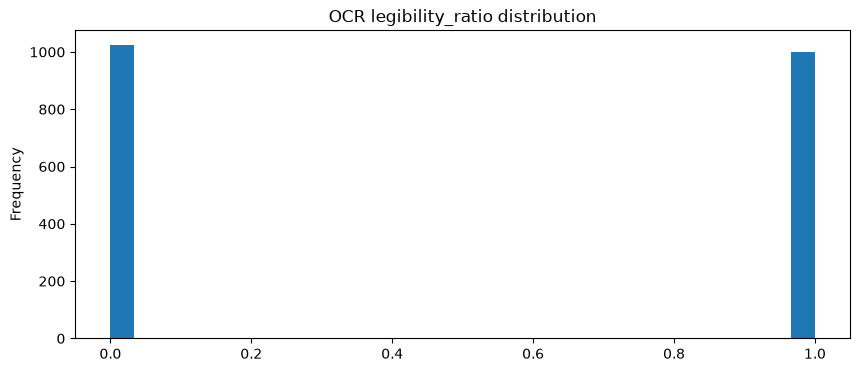


ocr_queue.csv (trang can OCR, CHUA co trong RAG corpus): 1,060 rows


In [19]:
try:
    tinix_manifest = pd.read_csv(PROJECT_ROOT / "data/processed/tinix_ingest_manifest.csv")
    print(f"tinix_ingest_manifest.csv: {len(tinix_manifest):,} rows")
    display(tinix_manifest["status"].value_counts().rename("count"))
    display(tinix_manifest.groupby("ticker").size().sort_values(ascending=False).rename("count"))
except Exception as e:
    print(f"[canh bao] khong doc duoc tinix_ingest_manifest.csv: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()

try:
    ingest_manifest = pd.read_csv(PROJECT_ROOT / "data/processed/ingest_manifest.csv")
    print(f"\ningest_manifest.csv (PDF that, pdf_ingest_router.py): {len(ingest_manifest):,} rows")
    display(ingest_manifest["status"].value_counts().rename("count"))
    display(ingest_manifest["ticker"].value_counts().rename("count"))
    if "legibility_ratio" in ingest_manifest.columns:
        ingest_manifest["legibility_ratio"].plot(kind="hist", bins=30, title="OCR legibility_ratio distribution")
        plt.show()
except Exception as e:
    print(f"[canh bao] khong doc duoc ingest_manifest.csv: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()

try:
    ocr_queue = pd.read_csv(PROJECT_ROOT / "data/processed/ocr_queue.csv")
    print(f"\nocr_queue.csv (trang can OCR, CHUA co trong RAG corpus): {len(ocr_queue):,} rows")
except Exception as e:
    print(f"[canh bao] khong doc duoc ocr_queue.csv: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()


## 8. Evaluation benchmark (`data/eval/benchmark.jsonl`)

Đây chính là tập nhãn nhỏ đang dùng để đánh giá router hiện tại (rule-based) — và cũng là
nơi cho thấy rõ nhất tại sao **chưa thể huấn luyện một learned router đáng tin** ngay bây
giờ: cần nhìn thẳng vào phân bố lớp thực tế của 12 câu này.


In [20]:
import json as _json

bench_path = PROJECT_ROOT / "data/eval/benchmark.jsonl"
try:
    items = [_json.loads(l) for l in bench_path.read_text(encoding="utf-8").splitlines() if l.strip()]
    bench = pd.DataFrame(items)
    print(f"benchmark.jsonl: {len(bench)} items")
    display(bench["category"].value_counts().rename("count"))
    if "expected_branch" in bench.columns:
        display(bench["expected_branch"].value_counts().rename("count"))
    print("\n[KET LUAN QUAN TRONG] Voi so luong nay, MOI class routing chi co 1-3 vi du "
          "- khong the tach train/val/test co y nghia, chua noi den huan luyen mot classifier "
          "that su tong quat hoa duoc. Can mo rong benchmark len it nhat vai tram cau hoi da dang "
          "cach dien dat truoc khi xay learned router (xem thao luan RQ1/RQ2 trong phien lam viec).")
except Exception as e:
    print(f"[canh bao] khong doc duoc benchmark.jsonl: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    bench = pd.DataFrame()


benchmark.jsonl: 12 items


category
routing               8
rag_temporal          2
whatif_exact_match    1
rag_faithfulness      1
Name: count, dtype: int64

expected_branch
rag                   4
whatif                4
dag                   1
causal                1
compare               1
whatif_unsupported    1
Name: count, dtype: int64


[KET LUAN QUAN TRONG] Voi so luong nay, MOI class routing chi co 1-3 vi du - khong the tach train/val/test co y nghia, chua noi den huan luyen mot classifier that su tong quat hoa duoc. Can mo rong benchmark len it nhat vai tram cau hoi da dang cach dien dat truoc khi xay learned router (xem thao luan RQ1/RQ2 trong phien lam viec).


## 9. Cross-cutting: ticker × modality coverage matrix

Bảng tổng hợp: với mỗi ticker trong `companies`, có đủ **4 loại dữ liệu** hay không — DAG
(financial_line_items), RAG (disclosure_chunks), Price (company_price_snapshot), Ratios
(financial_ratios). Đây là bảng quan trọng nhất để quyết định **tập ticker nào an toàn để
dùng khi mở rộng benchmark hoặc test model mới** — tránh chọn phải ticker chỉ có 1/4 loại dữ
liệu.


In [21]:
if not companies.empty:
    cov = companies[["ticker", "company_name", "sector"]].copy()
    cov["has_dag"] = cov["ticker"].isin(fli["ticker"].unique()) if not fli.empty else False
    cov["has_ratios"] = cov["ticker"].isin(fratios["ticker"].unique()) if not fratios.empty else False
    cov["has_price"] = cov["ticker"].isin(prices["ticker"].unique()) if not prices.empty else False
    cov["has_rag"] = cov["ticker"].isin(chunks_meta["ticker"].unique()) if not chunks_meta.empty else False
    cov["modality_count"] = cov[["has_dag", "has_ratios", "has_price", "has_rag"]].sum(axis=1)

    print("Phan bo so luong modality co san tren moi ticker:")
    display(cov["modality_count"].value_counts().sort_index().rename("n_tickers"))

    print("\nCac ticker co DU CA 4 modality (an toan nhat de dung lam vi du benchmark/test):")
    display(cov[cov["modality_count"] == 4][["ticker", "company_name", "sector"]])

    print("\nCac ticker CHUA co modality nao (0/4) - can loai khoi moi ke hoach eval gan day:")
    display(cov[cov["modality_count"] == 0][["ticker", "company_name", "sector"]].head(20))
else:
    print("[bo qua] khong co bang companies de doi chieu")


Phan bo so luong modality co san tren moi ticker:


modality_count
0      9
1    191
2      2
3     13
4      1
Name: n_tickers, dtype: int64


Cac ticker co DU CA 4 modality (an toan nhat de dung lam vi du benchmark/test):


,ticker,company_name,sector
175,CTD,CTCP Xây dựng Coteccons,Hàng hóa công nghiệp



Cac ticker CHUA co modality nao (0/4) - can loai khoi moi ke hoach eval gan day:


,ticker,company_name,sector
12,ACBS,Công ty TNHH Chứng khoán ACB,Dịch vụ tài chính
29,AISEC,CTCP Chứng khoán AIS,Dịch vụ tài chính
45,APSC,CTCP Chứng khoán Alpha,Dịch vụ tài chính
47,ART,CTCP Chứng khoán ARTEX,Dịch vụ tài chính
48,ASAM,CTCP Chứng khoán ASAM,Dịch vụ tài chính
68,Beta,CTCP Chứng khoán Beta,Dịch vụ tài chính
153,CMP,CTCP Cảng Chân Mây,Vận tải
169,CSCJ,CTCP Chứng khoán Capital,Dịch vụ tài chính
185,CVS,CTCP Chứng khoán CV,Dịch vụ tài chính


## 10. Tóm tắt & câu hỏi cần trả lời sau khi chạy notebook này

Điền vào đây SAU khi đã xem output thật ở trên (không đoán trước con số) — dùng để quyết
định giữa 3 hướng ML đang cân nhắc (learned router / market-regime classifier / ABSA):

1. **Learned Router:** benchmark hiện có bao nhiêu ví dụ/lớp (mục 8)? Cần mở rộng lên bao
   nhiêu là đủ? Ticker nào (mục 9) nên ưu tiên dùng để sinh thêm câu hỏi đa dạng?
2. **Market-regime classifier (RQ3):** `MKT_VNINDEX`/`MKT_GOLD_SJC`/`MKT_OIL_WTI`/
   `MKT_FOREX_VCB` (mục 3) có đủ độ dài chuỗi thời gian chưa? Nếu chuỗi còn quá ngắn (Airflow
   DAG mới chạy vài ngày), cần chờ thêm bao lâu, hay cần backfill dữ liệu lịch sử?
3. **Causal T-learner (RQ6, đã có):** cặp treatment→outcome nào (mục 5) có đủ quan sát để
   tin tưởng kết quả ATE? Cặp nào nên loại khỏi báo cáo vì mẫu quá nhỏ?
4. **ABSA (RQ5):** dựa trên corpus RAG (mục 6) — doctype nào có đủ văn bản định tính (không
   phải chỉ bảng số liệu) để làm input ABSA có ý nghĩa?
5. **Data gaps cần vá trước khi làm gì tiếp:** liệt kê từ các dòng `[canh bao]`/`[QUAN TRONG]`
   xuất hiện trong output phía trên.
